In [5]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import seaborn as sns
import numpy as np
from scipy.interpolate import griddata
from matplotlib.patches import Patch



MODEL = "VLF"
INPUT_PICKLE = Path('../Recast/VLF/VLF_smodels.pcl')


# Mass columns are the ones used in the uploaded SModelS notebooks.
MASS_COL = "mass.5000006"
DM_MASS_COL = "mass.5000022"
K_FACTOR = 1.0
R_CUT = 1.0 / K_FACTOR

SHOW_TOTAL_EXCLUSION = True
FILL_EXCLUDED_REGIONS = True
FILL_LEFT_MASS = 200.0     # Exactly as in plotExclusion-DirectSearches
FILL_ALPHA = 0.18          # Exactly as in plotExclusion-DirectSearches
BENCHMARK = (1500.0, 100.0)
SHOW_BENCHMARK = True
X_LIM = (300.0, 1750.0)
Y_LIM = (40.0, 500.0)
LEGEND_FONTSIZE = 15
INTERPOLATION_RESOLUTION = 200  # auxPlots original grid used to FIND the r=1 contours

# The PCHIP smoothing you used for Zprime, adapted to M_limit(deltaM).
SMOOTH_SIGMA = 1.2          # Gaussian width IN OUTPUT GRID POINTS; 0 disables smoothing
PCHIP_KNOT_SPACING = 2.0    # GeV in deltaM, knot spacing before dense PCHIP reconstruction
BOUNDARY_NPTS = 650         # dense common deltaM grid, including both Y_LIM endpoints
FILL_GAP_TOLERANCE_Y = 3.0   # GeV; only tiny gaps between supported contours
FILL_GAP_TOLERANCE_X = 20.0  # GeV; require neighboring masses to be close
# 'individual': transparent fills for each analysis, 'total': one neutral combined fill, 'none': no fill.
FILL_STYLE = 'individual'  # Colored analysis fills; 'total' for neutral, 'none' for contours only
# Optional targeted repair of *short internal* gaps only, based on the two contour
# endpoints. This does NOT extrapolate above or below the analysis contour's support.
# Set to {} to retain all raw discontinuities. Repairs are visualization-only.
ANALYSIS_GAP_REPAIR = {
    'CMS-SUS-19-010': {'max_delta_y': 32.0, 'max_delta_m': 85.0}
}
SHOW_REPAIR_DIAGNOSTICS = True
# Raw combined-all contour is saved but NOT used for the black line (it is interpolated independently).

# Distinct lines with matching translucent colors.
PALETTE = [
    "#0072B2",  # Blue
    "#E41A1C",  # Red
    "#009E73",  # Green
    "#984EA3",  # Purple
    "#F781BF",  # Pink
    "#00A6A6",  # Teal
    "#4D4D4D",  # Dark gray
]

pd.option_context('display.max_columns', -1)

pd.options.mode.chained_assignment = None #Disable copy warnings
# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)




## Load Results

In [6]:
if not INPUT_PICKLE.exists():
    raise FileNotFoundError(f"Run ../Recast/getSModelSData.ipynb first to generate {INPUT_PICKLE}.")
dataDF = pd.read_pickle(INPUT_PICKLE).reset_index(drop=True).copy()
for col in (MASS_COL, DM_MASS_COL):
    if col not in dataDF:
        raise KeyError(f"Mass column {col} not found. Available: {[c for c in dataDF if c.startswith('mass.')]}")
dataDF['deltaM'] = pd.to_numeric(dataDF[MASS_COL]) - pd.to_numeric(dataDF[DM_MASS_COL])

# Select only points with deltaM > 50 GeV and M > 500 GeV
dataDF = dataDF[(dataDF['deltaM'] > Y_LIM[0]) & (dataDF[MASS_COL] > X_LIM[0])].copy()


### Get list of excluded points and relevant analyses

In [7]:
excludedDF = dataDF[dataDF['ExptRes.result0.r'] > 1.0].copy()
print(f"Found {len(excludedDF)} excluded points (r>1) out of {len(dataDF)} total points.")

## Get minimal set of analyses excluding all excluded points.
excluded_analysis_ids = {}
for index, row in excludedDF.iterrows():
    for col in dataDF.columns:
        if col.startswith('ExptRes.result') and col.endswith('.r'):
            if row[col] > 1.0:
                anaID = row[col[:-2]+'.AnalysisID']
                excluded_analysis_ids.setdefault(anaID, [])
                excluded_analysis_ids[anaID].append(index)

excluded_analysis_ids_sorted = {anaID : excluded_analysis_ids[anaID] for anaID in sorted(excluded_analysis_ids.keys(), key=lambda x: len(excluded_analysis_ids[x]), reverse=True)}
excluded_analysis_ids = excluded_analysis_ids_sorted
print(f"{len(excluded_analysis_ids)} excluding analysis IDs")
for anaID,indices in sorted(excluded_analysis_ids.items(), key=lambda x: len(x), reverse=True):
    print(f"  {anaID}: {len(indices)} excluded points")

Found 352 excluded points (r>1) out of 720 total points.
23 excluding analysis IDs
  ATLAS-SUSY-2018-12: 286 excluded points
  CMS-SUS-20-002: 256 excluded points
  CMS-SUS-19-010: 248 excluded points
  CMS-SUS-19-006-agg: 235 excluded points
  ATLAS-SUSY-2018-08: 234 excluded points
  CMS-SUS-19-006: 208 excluded points
  CMS-SUS-19-009: 184 excluded points
  CMS-SUS-16-033: 176 excluded points
  ATLAS-SUSY-2016-16: 129 excluded points
  CMS-SUS-16-036: 82 excluded points
  CMS-SUS-16-051: 67 excluded points
  ATLAS-SUSY-2016-17: 61 excluded points
  CMS-SUS-17-010: 59 excluded points
  CMS-SUS-19-011: 59 excluded points
  CMS-SUS-16-050-agg: 59 excluded points
  ATLAS-SUSY-2016-15: 52 excluded points
  CMS-SUS-16-050: 51 excluded points
  CMS-PAS-SUS-16-052: 47 excluded points
  CMS-SUS-17-005: 46 excluded points
  CMS-PAS-SUS-16-052-agg: 45 excluded points
  ATLAS-SUSY-2015-02: 44 excluded points
  CMS-SUS-18-004: 44 excluded points
  CMS-SUS-16-009: 38 excluded points


## Get minimal set of analyses

In [8]:
minimal_sets = []
all_excluded_indices = set(excludedDF.index)
for size in range(len(excluded_analysis_ids) + 1):
    minimal_sets = []
    for analyses_set in combinations(excluded_analysis_ids.keys(), size):
        excluded_indices_by_set = set([])
        for anaID in analyses_set:
            excluded_indices_by_set.update(excluded_analysis_ids[anaID])
        if len(all_excluded_indices) != len(excluded_indices_by_set):
            continue
        if all_excluded_indices.issubset(excluded_indices_by_set):
            minimal_sets.append(analyses_set)
    if minimal_sets:
        break
if not minimal_sets:
    minimal_sets = [list(excluded_analysis_ids.keys())]
    
# Sort sets by total excluded points covered, descending.
minimal_sets = sorted(minimal_sets, key=lambda x: sum(len(excluded_analysis_ids[anaID]) for anaID in x), reverse=True)

for i,m_set in enumerate(minimal_sets):
    excluded_indices_by_set = set([])
    for anaID in m_set:
        excluded_indices_by_set.update(excluded_analysis_ids[anaID])
    print(f"\nMinimal set {i+1}:")
    print(f"  Excluded points: {len(excluded_indices_by_set)}")
    for anaID in m_set:
        print("  ", anaID, len(excluded_analysis_ids[anaID]), "excluded points")

# Use the first minimal set for plotting.
minimal_analyses = {anaID: excluded_analysis_ids[anaID] for anaID in minimal_sets[0]}


Minimal set 1:
  Excluded points: 352
   CMS-SUS-20-002 256 excluded points
   CMS-SUS-19-010 248 excluded points
   CMS-SUS-19-006-agg 235 excluded points


## Get dataframe for each analysis

In [9]:
anaDFDict = {}
anaColumns = np.array([col for col in dataDF.columns if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')])
rColumns = np.array([col for col in dataDF.columns if col.startswith('ExptRes.result') and col.endswith('.r')])
for anaID in minimal_analyses:
    anaDFDict[anaID] = dataDF.drop(columns=np.concatenate((anaColumns, rColumns))).copy()
    anaDFDict[anaID]['r'] = 0.0
    for irow,row in dataDF.iterrows():
        if not anaID in row[anaColumns].values:
            continue
        r_values = row[rColumns[np.where(row[anaColumns].values == anaID)]].values
        r = max(r_values)
        anaDFDict[anaID].loc[irow,'r'] = r



## Excluded scan points by analysis

In [10]:
color_by_analysis = {a: PALETTE[i % len(PALETTE)] for i, a in enumerate(minimal_analyses)}

In [11]:
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import PchipInterpolator

def smooth(x,y,sigma=1.0,npts=100):
    # Smooth in log-space on a uniform mass grid
    xg = np.linspace(x.min(), x.max(), npts)
    yg = PchipInterpolator(x, y)(xg)
    yg = gaussian_filter1d(yg, sigma=sigma, 
                           mode='nearest')
    return xg,yg

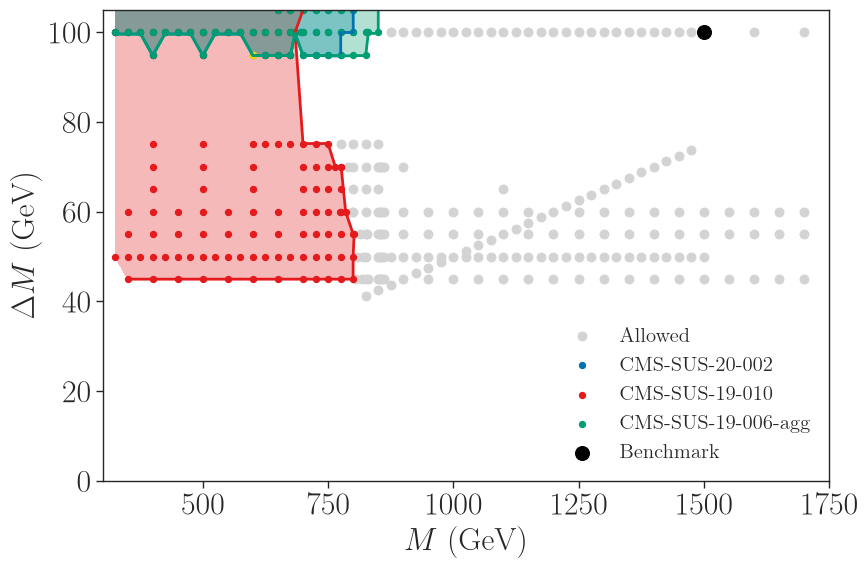

In [12]:
fig = plt.figure(figsize=(9, 6))
allowed = dataDF[~dataDF.index.isin(excludedDF.index)]
plt.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')

x = dataDF[MASS_COL].values
y = dataDF.deltaM.values
for ana,indices_excluded in minimal_analyses.items():
    anaDF = dataDF.loc[indices_excluded]
    plt.scatter(anaDF[MASS_COL], anaDF.deltaM, s=20, color=color_by_analysis[ana], label=ana)

    # z = 1 if the grid point is in the subset, 0 otherwise.
    z = np.array([1.0 if index in indices_excluded else 0.0 for index in dataDF.index])
    # Triangulate the irregular grid and draw the 0.5 boundary
    triang = tri.Triangulation(x, y)
    plt.tricontourf(triang, z, levels=[0.99, 10.1], colors=[color_by_analysis[ana]], alpha=0.3)  # filled region
    plt.tricontour(triang, z, levels=[0.99], colors=color_by_analysis[ana], linewidths=2)  


if SHOW_BENCHMARK:
    plt.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
plt.scatter(600, 95, color = 'gold')
plt.xlabel(r'$M$ (GeV)', fontsize=23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize=23)
plt.xlim(300, 1750)
plt.ylim(0,105)
plt.tick_params(axis='both', labelsize=23)
plt.legend(loc='lower right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.show()

Model: VLF
Existing mass pairs: 720
New mass pairs: 30

massPairs = [(600, 520), (625, 545), (650, 570), (675, 595), (700, 620), (725, 645), (750, 670), (775, 695), (800, 720), (600, 515), (625, 540), (650, 565), (675, 590), (700, 615), (725, 640), (750, 665), (775, 690), (800, 715), (625, 535), (650, 560), (675, 585), (700, 610), (725, 635), (750, 660), (775, 685), (800, 710), (775, 600), (800, 625), (775, 590), (800, 615)]

Saved: VLF_new_massPairs.txt


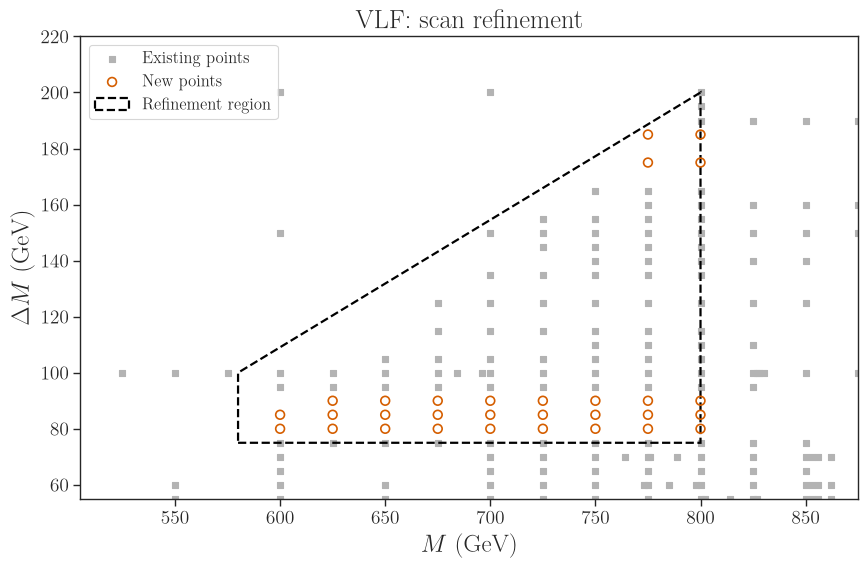

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import Polygon

# ============================================================
# Configuration
# ============================================================

MODEL = 'VLF'  # 'Scalar' or 'VLF'

MASS_STEP = 25  # GeV
DM_STEP = 10    # GeV

CONFIG = {
    'Scalar': {
        'parent_col': 'mass.5000002',
        'dm_col': 'mass.5000012',
        'polygon': [(340, 50), (550, 50),
                    (550, 160), (340, 160)],
        'extra_dm': [75, 85, 95, 105]
    },
    'VLF': {
        'parent_col': 'mass.5000006',
        'dm_col': 'mass.5000022',
        'polygon': [(580, 75), (800, 75),
                    (800, 200), (580, 100)],
        'extra_dm': [80, 90, 100, 125, 150, 175, 200]
    }
}

cfg = CONFIG[MODEL]
polygon = np.array(cfg['polygon'], dtype=float)

# ============================================================
# 1. Existing mass pairs
# ============================================================

existing_df = dataDF[
    [cfg['parent_col'], cfg['dm_col']]
].copy()

existing_df.columns = ['mass', 'mDM']
existing_df = existing_df.apply(pd.to_numeric, errors='coerce')
existing_df = existing_df.dropna().drop_duplicates()

existing_df['deltaM'] = existing_df.mass - existing_df.mDM

def mass_key(m, mdm):
    return (round(float(m), 5), round(float(mdm), 5))

existing_pairs = {
    mass_key(m, mdm)
    for m, mdm in zip(existing_df.mass, existing_df.mDM)
}

# ============================================================
# 2. Generate candidates within selected region
# ============================================================

mass_min, mass_max = polygon[:, 0].min(), polygon[:, 0].max()
dm_min, dm_max = polygon[:, 1].min(), polygon[:, 1].max()

masses = np.arange(
    np.ceil(mass_min / MASS_STEP) * MASS_STEP,
    mass_max + 1e-6, MASS_STEP
)

deltas = np.unique(np.r_[
    np.arange(dm_min, dm_max + 1e-6, DM_STEP),
    cfg['extra_dm'],
    dm_max
])

region = Path(polygon, closed=True)

rows = []

for dm in deltas:
    for mass in masses:
        mdm = mass - dm

        if mdm <= 0:
            continue

        # Only points inside the highlighted polygon
        if not region.contains_point((mass, dm), radius=1e-7):
            continue

        # Do not regenerate existing points
        if mass_key(mass, mdm) in existing_pairs:
            continue

        rows.append({
            'mass': float(mass),
            'mDM': float(mdm),
            'deltaM': float(dm)
        })

proposed = (
    pd.DataFrame(rows, columns=['mass', 'mDM', 'deltaM'])
    .drop_duplicates()
    .sort_values(['deltaM', 'mass'])
    .reset_index(drop=True)
)

# ============================================================
# 3. Generate massPairs array
# ============================================================

def clean_number(value):
    value = float(value)
    return int(value) if value.is_integer() else value

massPairs = [
    (clean_number(row.mass), clean_number(row.mDM))
    for row in proposed.itertuples()
]

print(f'Model: {MODEL}')
print(f'Existing mass pairs: {len(existing_pairs)}')
print(f'New mass pairs: {len(massPairs)}')

print('\nmassPairs =', repr(massPairs))

# Save a single-line array ready for the scan
filename = f'{MODEL}_new_massPairs.txt'

with open(filename, 'w') as f:
    f.write('massPairs = ' + repr(massPairs) + '\n')

print(f'\nSaved: {filename}')

# ============================================================
# 4. Visualize existing and proposed points
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    existing_df.mass, existing_df.deltaM,
    marker='s', s=20, color='0.7',
    label='Existing points', zorder=1
)

ax.scatter(
    proposed.mass, proposed.deltaM,
    marker='o', s=40, facecolors='none',
    edgecolors='#D55E00', linewidths=1.2,
    label='New points', zorder=3
)

ax.add_patch(Polygon(
    polygon, closed=True, fill=False,
    edgecolor='black', linewidth=1.6,
    linestyle='--', label='Refinement region'
))

ax.set_xlim(mass_min - 75, mass_max + 75)
ax.set_ylim(max(0, dm_min - 20), dm_max + 20)

ax.set_xlabel(r'$M$ (GeV)', fontsize=18)
ax.set_ylabel(r'$\Delta M$ (GeV)', fontsize=18)
ax.set_title(f'{MODEL}: scan refinement', fontsize=19)
ax.tick_params(labelsize=14)
ax.legend(fontsize=12)

fig.tight_layout()
plt.show()


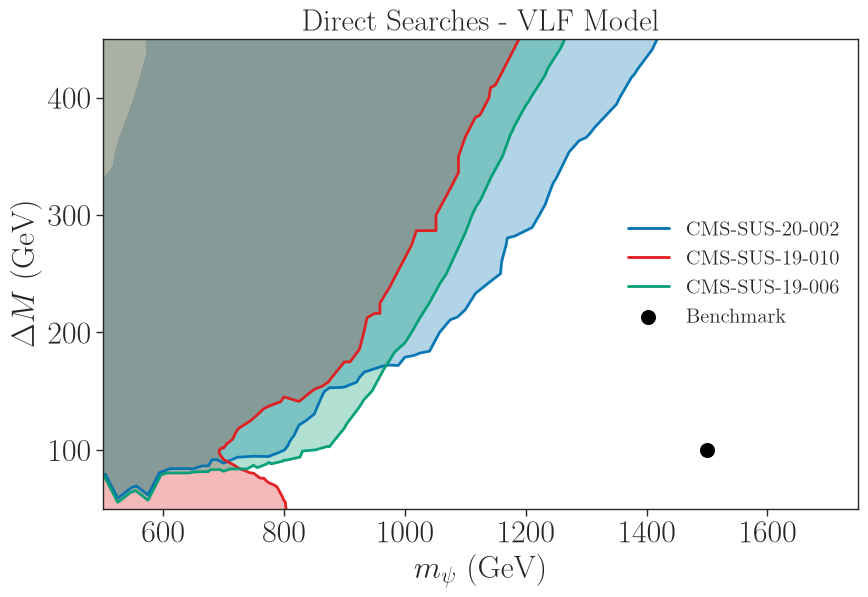

In [14]:
fig = plt.figure(figsize=(9, 6))
allowed = dataDF[~dataDF.index.isin(excludedDF.index)]
# plt.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')
for ana,anaDF_all in anaDFDict.items():
    label = ana.replace('-agg','')
    anaDF = anaDF_all.loc[anaDF_all['r'] > 1.0]
    # plt.scatter(anaDF[MASS_COL], anaDF.deltaM, s=20,
                # color=color_by_analysis[ana], label=label)
    x = anaDF_all[MASS_COL].values
    y = anaDF_all.deltaM.values
    z = anaDF_all.r.values
    xi = np.linspace(X_LIM[0], X_LIM[1], 3000)
    yi = np.linspace(Y_LIM[0], Y_LIM[1], 3000)
    X, Y = np.meshgrid(xi, yi)
    Z = griddata((x, y), z, (X, Y), method='linear', 
                 fill_value=0.0)
    # z = 1 if the grid point is in the subset, 0 otherwise.                                                                                                
    plt.contourf(X, Y, Z, levels=[1.0,100.0], 
                 colors=[color_by_analysis[ana]], alpha=0.3)
    contours = plt.contour(X, Y, Z, levels=[1.0], alpha=0.95,
                           colors=[color_by_analysis[ana]], linewidths=2.0, linestyles='solid')
    plt.plot([], [], color=color_by_analysis[ana], lw=2.0, label=label)   # legend proxy


if SHOW_BENCHMARK:
    plt.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
plt.xlabel(r'$m_{\psi}$ (GeV)', fontsize=23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize=23)
plt.xlim(500.0, X_LIM[1])
plt.ylim(50.,450.)
plt.tick_params(axis='both', labelsize=23)
plt.legend(loc='center right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.title('Direct Searches - VLF Model',fontsize=22)
plt.savefig('../paper_plots/directSearches_VLF.png',dpi=300, bbox_inches='tight')
plt.show()

CMS-SUS-19-010, points inside plot range: 590
  Valid r > 0: 334
  Reported r = 0: 0
  No usable CMS result: 256
  Excluded (r > 1): 248


,mpsi,deltaM,r
0,825.0,41.25,0.885166
1,850.0,42.50,0.758548
2,804.0,45.00,0.998396
3,800.0,50.00,1.032557
4,802.0,55.00,1.004165
5,798.0,60.00,0.995800
6,800.0,65.00,0.971597
7,789.0,70.00,0.978818
8,775.0,75.00,0.937400
9,650.0,95.00,1.072109


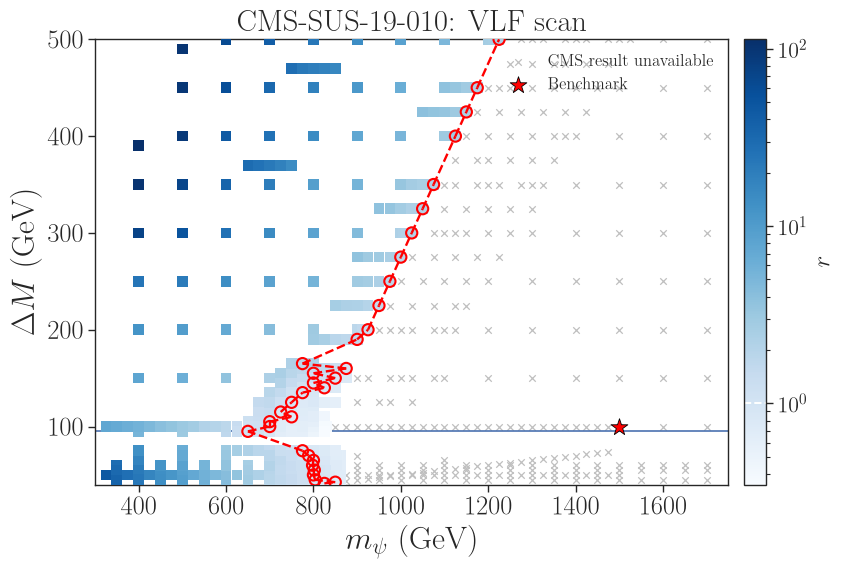

In [15]:
from matplotlib.colors import LogNorm

cms_analysis_id = 'CMS-SUS-19-010'
cms_r_column = 'r_cms_sus_19_010'

# Match each AnalysisID column with its own r column.  Do not assume
# that CMS-SUS-19-010 always appears in result0 or in minimal_analyses.
analysis_id_columns = [
    col for col in dataDF.columns
    if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')
]
matching_r_columns = []
for analysis_id_col in analysis_id_columns:
    r_col = analysis_id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF.columns:
        continue
    is_cms = dataDF[analysis_id_col].astype('string').str.strip().eq(cms_analysis_id).fillna(False)
    values = pd.to_numeric(dataDF[r_col], errors='coerce')
    matching_r_columns.append(values.where(is_cms))

if not matching_r_columns:
    raise ValueError('No paired SModelS AnalysisID/r columns found in the input data.')

# If CMS-SUS-19-010 is reported in several entries for one scan point,
# take the largest finite r. An entirely missing analysis stays NaN.
cms_r = pd.concat(matching_r_columns, axis=1).max(axis=1, skipna=True)

cms_scan = dataDF[[MASS_COL, 'deltaM']].copy()
cms_scan[cms_r_column] = cms_r
cms_scan = cms_scan.loc[
    cms_scan[MASS_COL].between(*X_LIM) & cms_scan['deltaM'].between(*Y_LIM)
].copy()

valid_positive = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].gt(0)
valid_zero = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].eq(0)
missing = ~np.isfinite(cms_scan[cms_r_column])
invalid_negative = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].lt(0)
if invalid_negative.any():
    raise ValueError('Negative CMS-SUS-19-010 r values found; check the SModelS results.')

print(f'CMS-SUS-19-010, points inside plot range: {len(cms_scan)}')
print(f'  Valid r > 0: {valid_positive.sum()}')
print(f'  Reported r = 0: {valid_zero.sum()}')
print(f'  No usable CMS result: {missing.sum()}')
print(f'  Excluded (r > 1): {(cms_scan[cms_r_column] > 1).sum()}')

fig, ax = plt.subplots(figsize=(9, 6))

if missing.any():
    ax.scatter(cms_scan.loc[missing, MASS_COL], cms_scan.loc[missing, 'deltaM'],
               marker='x', s=22, color='0.75', linewidths=0.9,
               label='CMS result unavailable', zorder=1)
if valid_zero.any():
    ax.scatter(cms_scan.loc[valid_zero, MASS_COL], cms_scan.loc[valid_zero, 'deltaM'],
               marker='s', s=34, color='0.4', label=r'$r=0$', zorder=2)

if valid_positive.any():
    positive_scan = cms_scan.loc[valid_positive]
    r_min = min(float(positive_scan[cms_r_column].min()), 1.0)
    r_max = max(float(positive_scan[cms_r_column].max()), 1.0)
    if r_min == r_max:
        r_min, r_max = r_min / 2, r_max * 2
    image = ax.scatter(positive_scan[MASS_COL], positive_scan['deltaM'],
                       c=positive_scan[cms_r_column], cmap='Blues',
                       norm=LogNorm(vmin=r_min, vmax=r_max),
                       marker='s', s=60, edgecolors='none', rasterized=True, zorder=3)
    colorbar = fig.colorbar(image, ax=ax, pad=0.02)
    colorbar.set_label(r'$r$', fontsize=18)
    # Mark the exclusion threshold on the color scale, if in range.
    if r_min <= 1 <= r_max:
        colorbar.ax.axhline(1, color='white', lw=1.4, ls='--')
else:
    print('No positive CMS-SUS-19-010 values to color on a logarithmic scale.')

if SHOW_BENCHMARK:
    ax.scatter(BENCHMARK[0], BENCHMARK[1], c='red', marker='*',
               edgecolors='black', linewidths=0.6, s=160,
               label='Benchmark', zorder=5)

from matplotlib.lines import Line2D

# ============================================================
# Approximate r=1 boundary using closest sampled points
# ============================================================

R_TOL = 1.60       # Accept 0.7 <= r <= 1.3
MAX_DM_GAP = 60    # Maximum gap for connecting adjacent rows

approx_points = []

for dm, g in cms_scan.groupby('deltaM'):
    g = g.copy()
    g[cms_r_column] = pd.to_numeric(g[cms_r_column], errors='coerce')

    g = g[
        np.isfinite(g[cms_r_column]) &
        (g[cms_r_column] > 0)
    ]

    if g.empty:
        continue

    # Choose point closest to r=1 in logarithmic space
    idx = np.abs(np.log(g[cms_r_column])).idxmin()
    p = g.loc[idx]

    if abs(p[cms_r_column]-1) <= R_TOL:
        approx_points.append({
            'mpsi': p[MASS_COL],
            'deltaM': dm,
            'r': p[cms_r_column]
        })

approx = pd.DataFrame(
    approx_points, columns=['mpsi', 'deltaM', 'r']
).sort_values('deltaM').reset_index(drop=True)

if not approx.empty:
    # Display approximate boundary points
    display(approx)

    ax.scatter(
        approx.mpsi, approx.deltaM,
        facecolors='none', edgecolors='red',
        marker='o', s=65, linewidths=1.5, zorder=6
    )

    # Connect only adjacent rows with sufficiently small gaps
    for i in range(len(approx)-1):
        a, b = approx.iloc[i], approx.iloc[i+1]

        if b.deltaM-a.deltaM <= MAX_DM_GAP:
            ax.plot(
                [a.mpsi, b.mpsi],
                [a.deltaM, b.deltaM],
                color='red', linestyle='--',
                linewidth=1.7, zorder=5
            )

    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D(
        [0], [0], color='red', linestyle='--', lw=1.7,
        label=r'Approximate $r\simeq1$'
    ))
    ax.legend(handles=handles, fontsize=12)

ax.axhline(95)
ax.set_xlim(*X_LIM)
ax.set_ylim(*Y_LIM)
ax.set_xlabel(r'$m_{\psi}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\Delta M$ (GeV)', fontsize=23)
ax.set_title('CMS-SUS-19-010: VLF scan', fontsize=22)
ax.set_xlim(300, 1750)
#ax.set_ylim(0, 175)
ax.tick_params(axis='both', labelsize=19)
if missing.any() or valid_zero.any() or SHOW_BENCHMARK:
    ax.legend(loc='upper right', framealpha=0, fontsize=12)
fig.tight_layout()

#cms_plot_dir = Path('../paper_plots')
#cms_plot_dir.mkdir(parents=True, exist_ok=True)
#cms_plot_path = cms_plot_dir / 'cms_sus_19_010_r_heatmap_vlf.png'
#fig.savefig(cms_plot_path, dpi=300, bbox_inches='tight')
#print('Saved:', cms_plot_path)
plt.show()


T2tt (CMS Fig. 8a): 110 published observed points, DeltaM = 93.15--1311.40 GeV
T2ttC (CMS Fig. 9a): 18 published observed points, DeltaM = 10.00--80.00 GeV
SModelS: 720 distinct scanned masses; 334 with r > 0


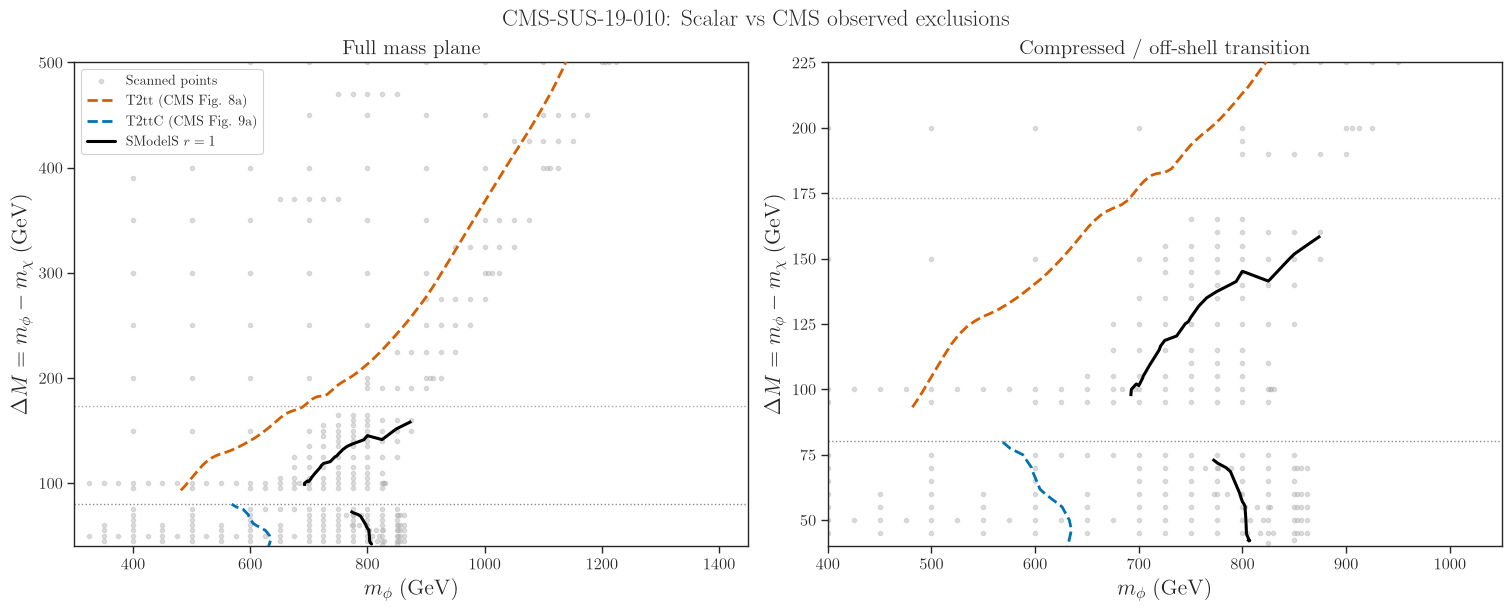

Mass differences are descriptive, NOT a validation of the same theory cross section.


,topology,deltaM,CMS_mass_GeV,SModelS_mass_GeV,difference_GeV
0,T2ttC (CMS Fig. 9a),45.0,634.32,803.75,169.44
1,T2ttC (CMS Fig. 9a),50.0,633.01,803.33,170.32
2,T2ttC (CMS Fig. 9a),55.0,626.08,802.76,176.67
3,T2ttC (CMS Fig. 9a),60.0,609.70,797.58,187.88
4,T2ttC (CMS Fig. 9a),65.0,601.38,795.56,194.18
5,T2ttC (CMS Fig. 9a),70.0,596.67,784.34,187.67
6,T2ttC (CMS Fig. 9a),75.0,588.10,766.74,178.64
7,T2tt (CMS Fig. 8a),95.0,484.83,684.95,200.13
8,T2tt (CMS Fig. 8a),100.0,492.81,692.85,200.04
9,T2tt (CMS Fig. 8a),105.0,500.26,704.24,203.98



Mean absolute mass difference (GeV) by CMS topology:


,count,mean,max
topology,,,
T2tt (CMS Fig. 8a),9,199.27,219.88
T2ttC (CMS Fig. 9a),7,180.69,194.18


In [16]:
# ============================================================
# CMS-SUS-19-010: SModelS Scalar r=1 vs published CMS contours
# Inputs: dataDF + the two uploaded HEPData Observed_Lines YAMLs.
# CMS Fig. 08(a): axes (m_stop, m_neutralino) -> convert to DeltaM.
# CMS Fig. 09(a): axes (m_stop, DeltaM), no conversion needed.
# These are OBSERVED exclusion contours, not cross-section UL grids.
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import yaml

ANALYSIS_ID = 'CMS-SUS-19-010'
PARENT_COL = MASS_COL            # Scalar notebook: mass.5000002
INVISIBLE_COL = DM_MASS_COL      # Scalar notebook: mass.5000012
MAX_MASS_GAP = 150.0            # Restrict triangulation to nearby scan points
MAX_DM_GAP = 60.0
MASK_TOPOLOGY_GAP = True         # Do not draw across the 80--93 GeV map gap
SHOW_SCAN_POINTS = True
SAVE_COMPARISON = True

FILES = {
    'T2tt (CMS Fig. 8a)': 'HEPData-ins1849522-v1-Figure_08-a_Observed_Lines.yaml',
    'T2ttC (CMS Fig. 9a)': 'HEPData-ins1849522-v1-Figure_09-a_Observed_Lines.yaml',
}
COLORS = {'T2tt (CMS Fig. 8a)': '#D55E00',
          'T2ttC (CMS Fig. 9a)': '#0072B2'}

def find_yaml(filename):
    # Works locally when YAMLs are placed next to the notebook,
    # and in this ChatGPT environment where uploads are mounted in /mnt/data.
    for directory in [Path.cwd(), Path.cwd().parent, Path('/mnt/data')]:
        candidate = directory / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'{filename}: place this YAML next to the notebook.')

def read_cms_observed(filename, *, figure08=False):
    with find_yaml(filename).open(encoding='utf-8') as f:
        doc = yaml.safe_load(f)
    x_entry = doc['independent_variables'][0]
    assert x_entry['header'].get('units') == 'GeV', 'Unexpected CMS mass units'
    dep = next(d for d in doc['dependent_variables']
               if 'Observed Exclusion Contour' in d['header']['name'])
    x = pd.to_numeric([v['value'] for v in x_entry['values']], errors='coerce')
    y = pd.to_numeric([v['value'] for v in dep['values']], errors='coerce')
    good = np.isfinite(x) & np.isfinite(y)
    m = np.asarray(x[good], dtype=float)
    z = np.asarray(y[good], dtype=float)
    dm = m - z if figure08 else z
    return pd.DataFrame({'mass': m, 'deltaM': dm})  # preserve HEPData line order

cms_lines = {
    label: read_cms_observed(file, figure08=('T2tt (' in label))
    for label, file in FILES.items()
}
for name, frame in cms_lines.items():
    print(f'{name}: {len(frame)} published observed points, '
          f'DeltaM = {frame.deltaM.min():.2f}--{frame.deltaM.max():.2f} GeV')

# Extract each r from its matching SModelS AnalysisID/r pair.
matched_r = []
for id_col in [c for c in dataDF if c.startswith('ExptRes.result') and c.endswith('.AnalysisID')]:
    r_col = id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF:
        continue
    mask = dataDF[id_col].astype('string').str.strip().eq(ANALYSIS_ID).fillna(False)
    matched_r.append(pd.to_numeric(dataDF[r_col], errors='coerce').where(mask))
if not matched_r:
    raise ValueError('No paired SModelS AnalysisID/r columns found')

scan_cms = dataDF[[PARENT_COL, INVISIBLE_COL]].copy()
scan_cms.columns = ['mass', 'mchi']
scan_cms['r'] = pd.concat(matched_r, axis=1).max(axis=1, skipna=True)
scan_cms[['mass', 'mchi', 'r']] = scan_cms[['mass', 'mchi', 'r']].apply(pd.to_numeric, errors='coerce')
scan_cms = scan_cms.dropna(subset=['mass', 'mchi'])
scan_cms = scan_cms.groupby(['mass', 'mchi'], as_index=False)['r'].max()
scan_cms['deltaM'] = scan_cms.mass - scan_cms.mchi
scan_cms = scan_cms.sort_values(['deltaM', 'mass'])

x = scan_cms.mass.to_numpy(float)
y = scan_cms.deltaM.to_numpy(float)
r = scan_cms.r.to_numpy(float)
valid = np.isfinite(r) & (r > 0)
print(f'SModelS: {len(scan_cms)} distinct scanned masses; {valid.sum()} with r > 0')

# Triangulation includes unavailable scan points, so triangles adjacent
# to an unavailable r are masked instead of crossing missing regions.
triang = None
if len(x) >= 3 and valid.sum() >= 3:
    triang = mtri.Triangulation(x, y)
    vertices = triang.triangles
    bad = (~valid[vertices]).any(axis=1)
    bad |= np.ptp(x[vertices], axis=1) > MAX_MASS_GAP
    bad |= np.ptp(y[vertices], axis=1) > MAX_DM_GAP
    if MASK_TOPOLOGY_GAP:
        # Avoid inventing a continuous r=1 boundary where the two CMS
        # topology interpretations have no published overlapping contour.
        bad |= ((y[vertices].min(axis=1) <= 80.0) &
                (y[vertices].max(axis=1) >= 93.15))
    triang.set_mask(bad)
    good_t = triang.get_masked_triangles()
    if not len(good_t) or not np.any((r[good_t].min(axis=1) <= 1) &
                                     (r[good_t].max(axis=1) >= 1)):
        triang = None

fig, axs = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, zoom in zip(axs, [False, True]):
    if SHOW_SCAN_POINTS:
        ax.scatter(x[valid], y[valid], s=10, color='0.7', alpha=0.45,
                   rasterized=True, zorder=1, label='Scanned points' if not zoom else None)
    if triang is not None:
        log_r = np.zeros_like(r)
        log_r[valid] = np.log10(r[valid])
        ax.tricontour(triang, log_r, levels=[0.0], colors=['black'],
                      linewidths=2.2, zorder=4)
    for name, frame in cms_lines.items():
        ax.plot(frame.mass, frame.deltaM, ls='--', lw=2.0,
                color=COLORS[name], label=name, zorder=5)
    ax.axhline(80.4, color='0.55', lw=1.0, ls=':', zorder=0)
    ax.axhline(173.0, color='0.65', lw=1.0, ls=':', zorder=0)
    ax.set_xlabel(r'$m_\phi\; (\mathrm{GeV})$', fontsize=16)
    ax.set_ylabel(r'$\Delta M = m_\phi-m_\chi\; (\mathrm{GeV})$', fontsize=16)
    ax.set_xlim(300, 1450) if not zoom else ax.set_xlim(400, 1050)
    ax.set_ylim(40, 500) if not zoom else ax.set_ylim(40, 225)
    ax.tick_params(labelsize=12)
    ax.set_title('Full mass plane' if not zoom else 'Compressed / off-shell transition', fontsize=15)
axs[0].plot([], [], color='black', lw=2.2, label=r'SModelS $r=1$')
axs[0].legend(loc='upper left', fontsize=10, framealpha=0.9)
fig.suptitle('CMS-SUS-19-010: Scalar vs CMS observed exclusions', fontsize=17)
if SAVE_COMPARISON:
    out = Path('../paper_plots')
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / 'CMS_SUS_19_010_Scalar_vs_HEPData.png', dpi=300, bbox_inches='tight')
plt.show()

# Quantitative comparison at common DeltaM values (NO extrapolation).
# A row is compared only when exactly one adjacent positive-r pair brackets r=1.
def row_crossings(group):
    group = group.sort_values('mass')
    xx, rr = group.mass.to_numpy(float), group.r.to_numpy(float)
    roots = []
    for i in range(len(xx)-1):
        if xx[i+1] - xx[i] > MAX_MASS_GAP:
            continue
        if not (np.isfinite(rr[i]) and np.isfinite(rr[i+1]) and rr[i] > 0 and rr[i+1] > 0):
            continue
        a, b = np.log(rr[i]), np.log(rr[i+1])
        if a == 0:
            roots.append(xx[i])
        elif a * b < 0:
            roots.append(xx[i] - a*(xx[i+1]-xx[i])/(b-a))
    if len(xx) and np.isfinite(rr[-1]) and np.isclose(rr[-1], 1, atol=1e-10):
        roots.append(xx[-1])
    return np.unique(np.round(roots, 6))

rows_comparison = []
for dm, group in scan_cms.groupby('deltaM'):
    roots = row_crossings(group)
    for name, line in cms_lines.items():
        dms = line.deltaM.to_numpy(float)
        if len(roots) != 1 or dm < dms.min() or dm > dms.max():
            continue
        cms_mass = float(np.interp(dm, dms, line.mass.to_numpy(float)))
        sm_mass = float(roots[0])
        rows_comparison.append({'topology': name, 'deltaM': dm,
                                'CMS_mass_GeV': cms_mass, 'SModelS_mass_GeV': sm_mass,
                                'difference_GeV': sm_mass - cms_mass})
comparison_cms_smodels = pd.DataFrame(rows_comparison,
    columns=['topology', 'deltaM', 'CMS_mass_GeV', 'SModelS_mass_GeV', 'difference_GeV'])
print('Mass differences are descriptive, NOT a validation of the same theory cross section.')
if comparison_cms_smodels.empty:
    print('No common DeltaM rows with exactly one supported SModelS r=1 crossing.')
else:
    display(comparison_cms_smodels.round(2))
    print('\nMean absolute mass difference (GeV) by CMS topology:')
    display(comparison_cms_smodels.assign(abs_diff=lambda d: d.difference_GeV.abs())
            .groupby('topology')['abs_diff'].agg(['count','mean','max']).round(2))


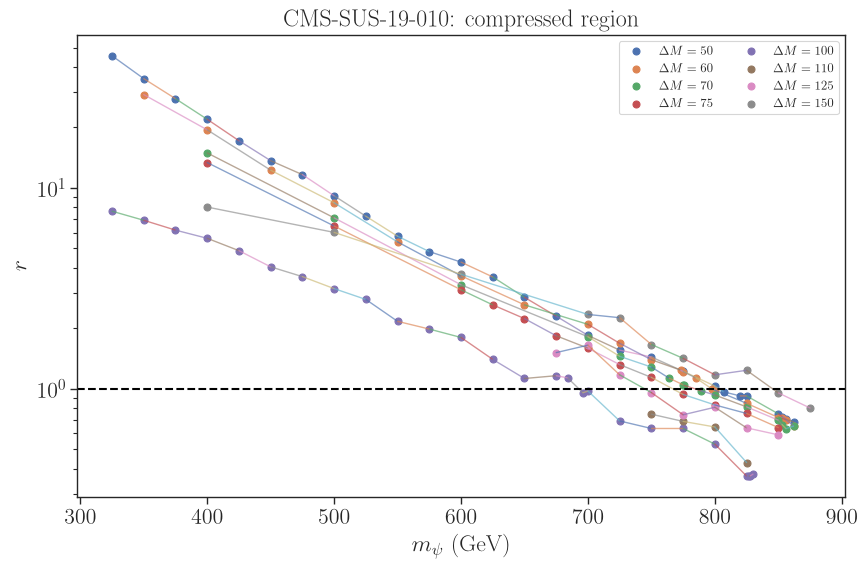

,deltaM,nearest_mass,nearest_r,n_crossings,interpolated_masses
0,50,800.0,1.032557,1,[803.3]
1,60,798.0,0.995800,1,[797.6]
2,70,789.0,0.978818,1,[784.3]
3,75,775.0,0.937400,1,[766.7]
4,100,700.0,0.974750,1,[692.9]
5,110,750.0,0.747643,0,[]
6,125,750.0,0.957380,1,[744.7]
7,150,850.0,0.954416,1,[845.5]


In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DM_VALUES = [50, 60, 70, 75, 80, 90, 100, 110, 125, 150]
MAX_MASS_GAP = 100

df = cms_scan[[MASS_COL, 'deltaM', cms_r_column]].copy()
df.columns = ['mass', 'dm', 'r']
df = df.apply(pd.to_numeric, errors='coerce')
df = df.groupby(['dm', 'mass'], as_index=False)['r'].max()

results = []

fig, ax = plt.subplots(figsize=(9, 6))

for dm in DM_VALUES:
    g = df[np.isclose(df.dm, dm)].sort_values('mass')
    if g.empty:
        continue

    x = g.mass.to_numpy(float)
    r = g.r.to_numpy(float)
    valid = np.isfinite(r) & (r > 0)

    if not valid.any():
        continue

    # Closest existing point to r=1
    ids = np.flatnonzero(valid)
    nearest = ids[np.argmin(abs(np.log(r[ids])))]

    # Actual r=1 crossings between adjacent valid points
    crossings = []

    for i in range(len(x)-1):
        if not (valid[i] and valid[i+1]):
            continue
        if x[i+1]-x[i] > MAX_MASS_GAP:
            continue

        if np.isclose(r[i], 1, atol=1e-10):
            crossings.append(x[i])
        elif (r[i]-1)*(r[i+1]-1) < 0:
            root = x[i] - np.log(r[i])*(
                x[i+1]-x[i]
            )/(np.log(r[i+1])-np.log(r[i]))
            crossings.append(root)

    if valid[-1] and np.isclose(r[-1], 1, atol=1e-10):
        crossings.append(x[-1])

    results.append({
        'deltaM': dm,
        'nearest_mass': x[nearest],
        'nearest_r': r[nearest],
        'n_crossings': len(crossings),
        'interpolated_masses': np.round(crossings, 1).tolist()
    })

    ax.scatter(x[valid], r[valid], s=25, label=rf'$\Delta M={dm}$')

    # Connect only sufficiently close, valid neighboring points.
    for i in range(len(x)-1):
        if valid[i] and valid[i+1] and x[i+1]-x[i] <= MAX_MASS_GAP:
            ax.plot(x[i:i+2], r[i:i+2], lw=1, alpha=0.65)

ax.axhline(1, color='black', ls='--', lw=1.5)
ax.set_yscale('log')
ax.set_xlabel(r'$m_\psi$ (GeV)', fontsize=17)
ax.set_ylabel(r'$r$', fontsize=17)
ax.set_title('CMS-SUS-19-010: compressed region')
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

diagnostic = pd.DataFrame(results)
display(diagnostic)


,mpsi,deltaM,T2ttC,T2ttoff,T2tt
0,700,50,145.424,NaN,NaN
1,700,55,139.846,NaN,NaN
2,700,60,128.654,NaN,NaN
3,700,65,133.584,NaN,NaN
4,700,70,150.330,NaN,NaN
...,...,...,...,...,...
58,800,130,NaN,141.203,NaN
59,800,135,NaN,135.205,NaN
60,800,140,NaN,128.852,NaN
61,800,145,NaN,118.916,NaN


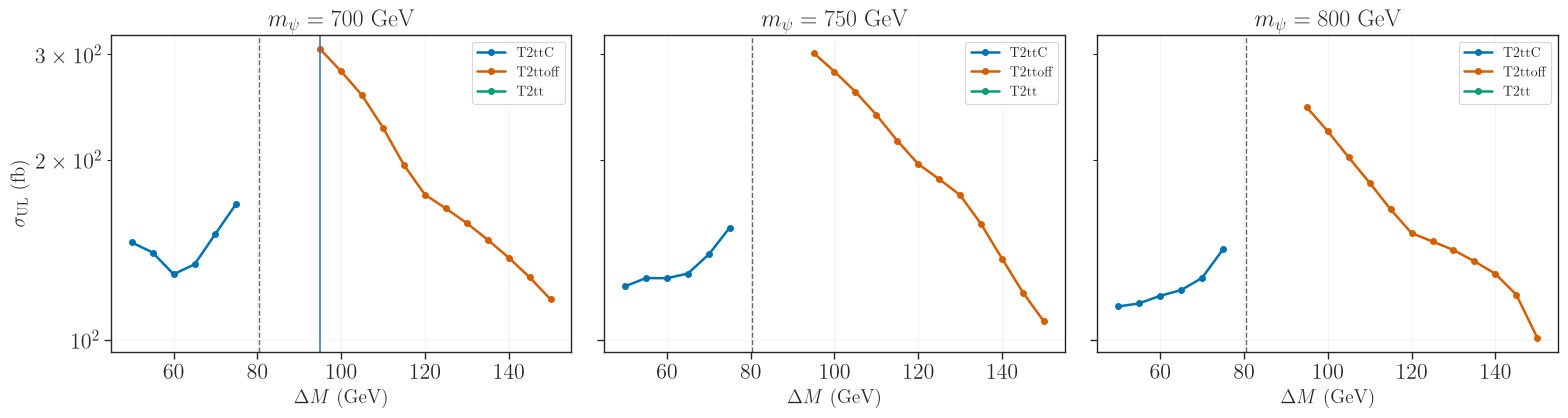

In [18]:

from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV, fb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db = Database('official')
exps = db.getExpResults(analysisIDs=['CMS-SUS-19-010'])

tx_maps = {
    name: next(
        (tx for exp in exps for tx in exp.getTxNames()
         if tx.txName == name and tx.dataType == 'upperLimit'),
        None
    )
    for name in ['T2ttC', 'T2ttoff', 'T2tt']
}

def get_ul_value(tx, mpsi, dm):
    if tx is None or mpsi <= dm:
        return np.nan

    mphi = mpsi - dm
    masses = [
        [float(mpsi)*GeV, float(mphi)*GeV],
        [float(mpsi)*GeV, float(mphi)*GeV]
    ]

    point = tx.transformPoint(masses)
    ul = tx.getULFor(sms=None, mass=point)

    return np.nan if ul is None else float(ul.asNumber(fb))

# Compare map coverage and upper limits at fixed masses
MASS_VALUES = [700, 750, 800]
DM_VALUES = np.arange(50, 151, 5)

records = []

for mpsi in MASS_VALUES:
    for dm in DM_VALUES:
        row = {'mpsi': mpsi, 'deltaM': dm}

        for name, tx in tx_maps.items():
            row[name] = get_ul_value(tx, mpsi, dm)

        records.append(row)

ul_comparison = pd.DataFrame(records)

display(ul_comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

colors = {
    'T2ttC': '#0072B2',
    'T2ttoff': '#D55E00',
    'T2tt': '#009E73'
}

for ax, mass in zip(axes, MASS_VALUES):
    subset = ul_comparison[ul_comparison.mpsi == mass]

    for name, color in colors.items():
        ax.plot(
            subset.deltaM, subset[name],
            'o-', color=color, lw=1.8, ms=4,
            label=name
        )

    ax.axvline(80.4, color='0.4', ls='--', lw=1)
    ax.set_title(rf'$m_\psi={mass}$ GeV')
    ax.set_xlabel(r'$\Delta M$ (GeV)', fontsize=14)
    ax.set_yscale('log')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.2)
axes[0].axvline(95)
axes[0].set_ylabel(r'$\sigma_{\rm UL}$ (fb)', fontsize=14)
fig.tight_layout()
plt.show()


,mpsi,deltaM,T2ttC,T2ttoff,T2tt
0,700,50,145.424,NaN,NaN
1,700,55,139.846,NaN,NaN
2,700,60,128.654,NaN,NaN
3,700,65,133.584,NaN,NaN
4,700,70,150.330,NaN,NaN
...,...,...,...,...,...
88,800,180,NaN,NaN,44.6230
89,800,185,NaN,NaN,40.8222
90,800,190,NaN,NaN,41.3937
91,800,195,NaN,NaN,41.1695


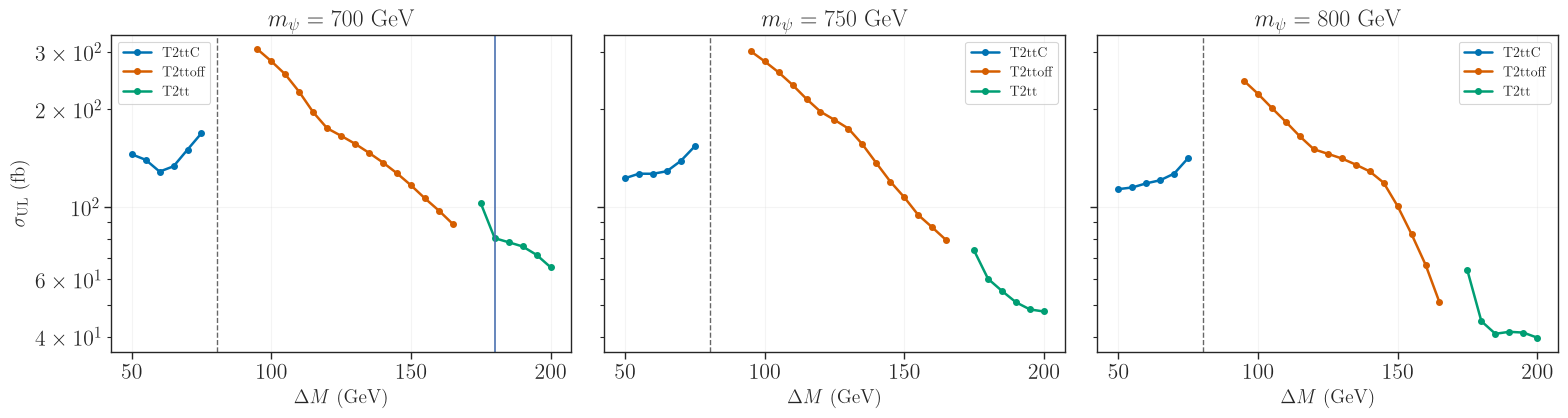

In [19]:

from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV, fb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db = Database('official')
exps = db.getExpResults(analysisIDs=['CMS-SUS-19-010'])

tx_maps = {
    name: next(
        (tx for exp in exps for tx in exp.getTxNames()
         if tx.txName == name and tx.dataType == 'upperLimit'),
        None
    )
    for name in ['T2ttC', 'T2ttoff', 'T2tt']
}

def get_ul_value(tx, mpsi, dm):
    if tx is None or mpsi <= dm:
        return np.nan

    mphi = mpsi - dm
    masses = [
        [float(mpsi)*GeV, float(mphi)*GeV],
        [float(mpsi)*GeV, float(mphi)*GeV]
    ]

    point = tx.transformPoint(masses)
    ul = tx.getULFor(sms=None, mass=point)

    return np.nan if ul is None else float(ul.asNumber(fb))

# Compare map coverage and upper limits at fixed masses
MASS_VALUES = [700, 750, 800]
DM_VALUES = np.arange(50, 205, 5)

records = []

for mpsi in MASS_VALUES:
    for dm in DM_VALUES:
        row = {'mpsi': mpsi, 'deltaM': dm}

        for name, tx in tx_maps.items():
            row[name] = get_ul_value(tx, mpsi, dm)

        records.append(row)

ul_comparison = pd.DataFrame(records)

display(ul_comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

colors = {
    'T2ttC': '#0072B2',
    'T2ttoff': '#D55E00',
    'T2tt': '#009E73'
}

for ax, mass in zip(axes, MASS_VALUES):
    subset = ul_comparison[ul_comparison.mpsi == mass]

    for name, color in colors.items():
        ax.plot(
            subset.deltaM, subset[name],
            'o-', color=color, lw=1.8, ms=4,
            label=name
        )

    ax.axvline(80.4, color='0.4', ls='--', lw=1)
    ax.set_title(rf'$m_\psi={mass}$ GeV')
    ax.set_xlabel(r'$\Delta M$ (GeV)', fontsize=14)
    ax.set_yscale('log')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.2)
axes[0].axvline(180)
axes[0].set_ylabel(r'$\sigma_{\rm UL}$ (fb)', fontsize=14)
fig.tight_layout()
plt.show()


Analysis: CMS-SUS-19-010
Total points: 720
Valid r > 0: 334
r = 0: 0
No stored r: 386
Excluded (r > 1): 248


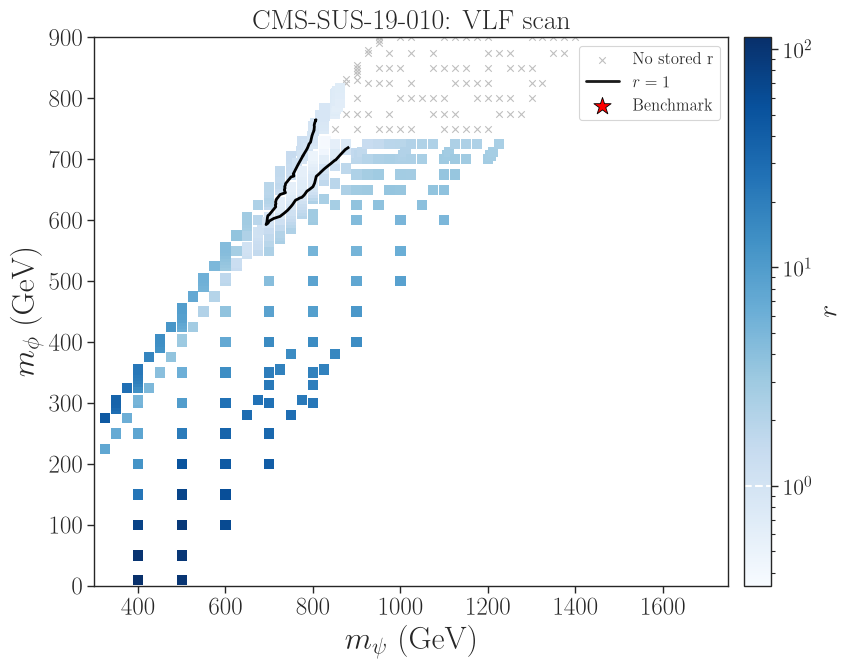

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

# ============================================================
# Configuration
# ============================================================

ANALYSIS_ID = 'CMS-SUS-19-010'  # Change the analysis here
MPSI_COL = 'mass.5000006'
MPHI_COL = 'mass.5000022'

SHOW_R1_CONTOUR = True
SHOW_BENCHMARK_POINT = True
MAX_DX = 150   # Maximum mass separation for contour interpolation
MAX_DDM = 60   # Maximum deltaM separation for contour interpolation

# ============================================================
# 1. Extract r for the selected analysis
# ============================================================

id_cols = [
    col for col in dataDF.columns
    if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')
]

matched = []

for id_col in id_cols:
    r_col = id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF.columns:
        continue

    mask = dataDF[id_col].astype('string').str.strip().eq(
        ANALYSIS_ID
    ).fillna(False)

    r_values = pd.to_numeric(dataDF[r_col], errors='coerce')
    matched.append(r_values.where(mask))

if not matched:
    raise ValueError('No matching AnalysisID/r column pairs found.')

r_analysis = pd.concat(matched, axis=1).max(axis=1)

# Build dataframe
plotDF = dataDF[[MPSI_COL, MPHI_COL]].copy()
plotDF['r'] = r_analysis

plotDF.columns = ['mpsi', 'mphi', 'r']
plotDF = plotDF.apply(pd.to_numeric, errors='coerce')
plotDF = plotDF.dropna(subset=['mpsi', 'mphi'])

# Remove duplicate mass pairs
plotDF = (
    plotDF.groupby(['mpsi', 'mphi'], as_index=False)['r']
    .max()
)

plotDF['deltaM'] = plotDF.mpsi - plotDF.mphi

valid = np.isfinite(plotDF.r) & (plotDF.r > 0)
zero = np.isfinite(plotDF.r) & (plotDF.r == 0)
missing = ~np.isfinite(plotDF.r)

print(f'Analysis: {ANALYSIS_ID}')
print(f'Total points: {len(plotDF)}')
print(f'Valid r > 0: {valid.sum()}')
print(f'r = 0: {zero.sum()}')
print(f'No stored r: {missing.sum()}')
print(f'Excluded (r > 1): {(plotDF.r > 1).sum()}')

# ============================================================
# 2. Plot
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

if missing.any():
    ax.scatter(
        plotDF.loc[missing, 'mpsi'],
        plotDF.loc[missing, 'mphi'],
        marker='x', s=22, c='0.75',
        linewidths=0.8, label='No stored r',
        zorder=1
    )

if zero.any():
    ax.scatter(
        plotDF.loc[zero, 'mpsi'],
        plotDF.loc[zero, 'mphi'],
        marker='s', s=30, c='0.5',
        label=r'$r=0$', zorder=2
    )

if valid.any():
    positive = plotDF.loc[valid]

    r_min = min(float(positive.r.min()), 1.0)
    r_max = max(float(positive.r.max()), 1.0)

    if r_min == r_max:
        r_min /= 2
        r_max *= 2

    image = ax.scatter(
        positive.mpsi, positive.mphi,
        c=positive.r,
        cmap='Blues',
        norm=LogNorm(vmin=r_min, vmax=r_max),
        marker='s', s=55,
        edgecolors='none',
        rasterized=True,
        zorder=3
    )

    cb = fig.colorbar(image, ax=ax, pad=0.02)
    cb.set_label(r'$r$', fontsize=20)
    cb.ax.axhline(1, color='white', ls='--', lw=1.5)

# ============================================================
# 3. Interpolated r = 1 contour (optional)
# ============================================================

if SHOW_R1_CONTOUR and len(plotDF) >= 3 and valid.sum() >= 3:
    x = plotDF.mpsi.to_numpy(float)
    y = plotDF.mphi.to_numpy(float)
    dm = plotDF.deltaM.to_numpy(float)
    r = plotDF.r.to_numpy(float)

    triang = mtri.Triangulation(x, y)
    t = triang.triangles

    bad_vertices = (~(np.isfinite(r) & (r > 0)))[t].any(axis=1)
    bad_geometry = (
        (np.ptp(x[t], axis=1) > MAX_DX) |
        (np.ptp(dm[t], axis=1) > MAX_DDM)
    )

    triang.set_mask(bad_vertices | bad_geometry)
    good = triang.get_masked_triangles()

    if len(good):
        rv = r[good]
        crosses = (rv.min(axis=1) <= 1) & (rv.max(axis=1) >= 1)

        if crosses.any():
            logr = np.zeros_like(r)
            good_r = np.isfinite(r) & (r > 0)
            logr[good_r] = np.log10(r[good_r])

            ax.tricontour(
                triang, logr, levels=[0],
                colors='black', linewidths=2,
                zorder=4
            )

            ax.plot([], [], 'k-', lw=2, label=r'$r=1$')
        else:
            print('No supported r=1 crossing found.')

# ============================================================
# 4. Benchmark
# ============================================================

if SHOW_BENCHMARK_POINT and 'BENCHMARK' in globals():
    # BENCHMARK = (mpsi, deltaM) in the original notebook
    bm_mpsi, bm_dm = BENCHMARK
    bm_mphi = bm_mpsi - bm_dm

    ax.scatter(
        bm_mpsi, bm_mphi,
        marker='*', c='red', s=170,
        edgecolors='black', linewidths=0.6,
        label='Benchmark', zorder=6
    )

# ============================================================
# 5. Style
# ============================================================

ax.set_xlim(*X_LIM)
ax.set_ylim([0,900])

ax.set_xlabel(r'$m_{\psi}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$m_{\phi}$ (GeV)', fontsize=23)
ax.set_title(f'{ANALYSIS_ID}: VLF scan', fontsize=20)

ax.tick_params(axis='both', labelsize=18)
ax.legend(loc='best', fontsize=12)

fig.tight_layout()
plt.show()


CMS-SUS-19-010, points inside plot range: 590
  Valid r > 0: 362
  Reported r = 0: 0
  No usable CMS result: 228
  Excluded (r > 1): 235


,mpsi,deltaM,r
0,825.0,95.0,1.065588
1,850.0,100.0,1.001553
2,800.0,105.0,1.311879
3,825.0,110.0,1.223056
4,800.0,115.0,1.439238
5,900.0,125.0,1.045345
6,800.0,135.0,2.016376
7,850.0,140.0,1.516418
8,800.0,145.0,2.251910
9,925.0,150.0,1.113150


Saved: ../paper_plots/cms_sus_19_010_r_heatmap_vlf.png


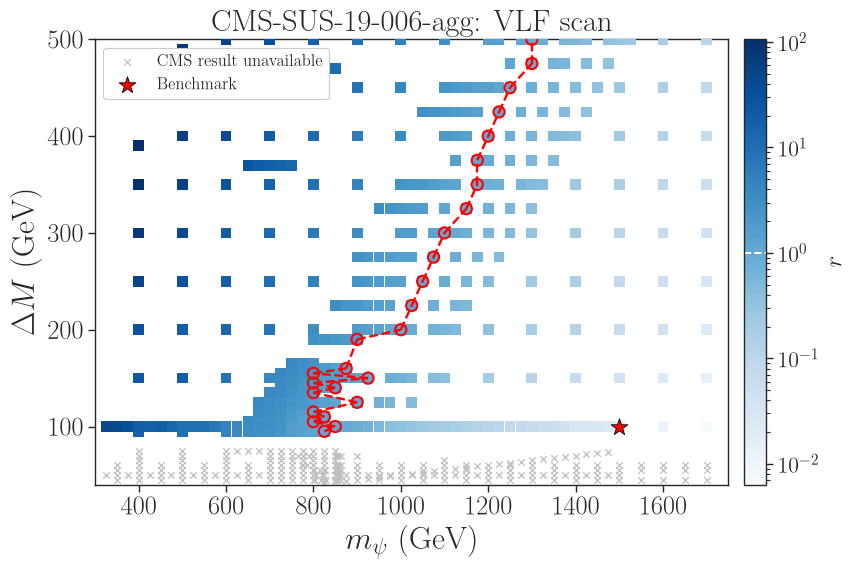

In [21]:
from matplotlib.colors import LogNorm

cms_analysis_id = 'CMS-SUS-19-006-agg'
cms_r_column = 'r_cms_sus_19_006-agg'

# Match each AnalysisID column with its own r column.  Do not assume
# that CMS-SUS-19-010 always appears in result0 or in minimal_analyses.
analysis_id_columns = [
    col for col in dataDF.columns
    if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')
]
matching_r_columns = []
for analysis_id_col in analysis_id_columns:
    r_col = analysis_id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF.columns:
        continue
    is_cms = dataDF[analysis_id_col].astype('string').str.strip().eq(cms_analysis_id).fillna(False)
    values = pd.to_numeric(dataDF[r_col], errors='coerce')
    matching_r_columns.append(values.where(is_cms))

if not matching_r_columns:
    raise ValueError('No paired SModelS AnalysisID/r columns found in the input data.')

# If CMS-SUS-19-010 is reported in several entries for one scan point,
# take the largest finite r. An entirely missing analysis stays NaN.
cms_r = pd.concat(matching_r_columns, axis=1).max(axis=1, skipna=True)

cms_scan = dataDF[[MASS_COL, 'deltaM']].copy()
cms_scan[cms_r_column] = cms_r
cms_scan = cms_scan.loc[
    cms_scan[MASS_COL].between(*X_LIM) & cms_scan['deltaM'].between(*Y_LIM)
].copy()

valid_positive = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].gt(0)
valid_zero = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].eq(0)
missing = ~np.isfinite(cms_scan[cms_r_column])
invalid_negative = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].lt(0)
if invalid_negative.any():
    raise ValueError('Negative CMS-SUS-19-010 r values found; check the SModelS results.')

print(f'CMS-SUS-19-010, points inside plot range: {len(cms_scan)}')
print(f'  Valid r > 0: {valid_positive.sum()}')
print(f'  Reported r = 0: {valid_zero.sum()}')
print(f'  No usable CMS result: {missing.sum()}')
print(f'  Excluded (r > 1): {(cms_scan[cms_r_column] > 1).sum()}')

fig, ax = plt.subplots(figsize=(9, 6))

if missing.any():
    ax.scatter(cms_scan.loc[missing, MASS_COL], cms_scan.loc[missing, 'deltaM'],
               marker='x', s=22, color='0.75', linewidths=0.9,
               label='CMS result unavailable', zorder=1)
if valid_zero.any():
    ax.scatter(cms_scan.loc[valid_zero, MASS_COL], cms_scan.loc[valid_zero, 'deltaM'],
               marker='s', s=34, color='0.4', label=r'$r=0$', zorder=2)

if valid_positive.any():
    positive_scan = cms_scan.loc[valid_positive]
    r_min = min(float(positive_scan[cms_r_column].min()), 1.0)
    r_max = max(float(positive_scan[cms_r_column].max()), 1.0)
    if r_min == r_max:
        r_min, r_max = r_min / 2, r_max * 2
    image = ax.scatter(positive_scan[MASS_COL], positive_scan['deltaM'],
                       c=positive_scan[cms_r_column], cmap='Blues',
                       norm=LogNorm(vmin=r_min, vmax=r_max),
                       marker='s', s=60, edgecolors='none', rasterized=True, zorder=3)
    colorbar = fig.colorbar(image, ax=ax, pad=0.02)
    colorbar.set_label(r'$r$', fontsize=18)
    # Mark the exclusion threshold on the color scale, if in range.
    if r_min <= 1 <= r_max:
        colorbar.ax.axhline(1, color='white', lw=1.4, ls='--')
else:
    print('No positive CMS-SUS-19-010 values to color on a logarithmic scale.')

if SHOW_BENCHMARK:
    ax.scatter(BENCHMARK[0], BENCHMARK[1], c='red', marker='*',
               edgecolors='black', linewidths=0.6, s=160,
               label='Benchmark', zorder=5)

from matplotlib.lines import Line2D

# ============================================================
# Approximate r=1 boundary using closest sampled points
# ============================================================

R_TOL = 1.50       # Accept 0.7 <= r <= 1.3
MAX_DM_GAP = 60    # Maximum gap for connecting adjacent rows

approx_points = []

for dm, g in cms_scan.groupby('deltaM'):
    g = g.copy()
    g[cms_r_column] = pd.to_numeric(g[cms_r_column], errors='coerce')

    g = g[
        np.isfinite(g[cms_r_column]) &
        (g[cms_r_column] > 0)
    ]

    if g.empty:
        continue

    # Choose point closest to r=1 in logarithmic space
    idx = np.abs(np.log(g[cms_r_column])).idxmin()
    p = g.loc[idx]

    if abs(p[cms_r_column]-1) <= R_TOL:
        approx_points.append({
            'mpsi': p[MASS_COL],
            'deltaM': dm,
            'r': p[cms_r_column]
        })

approx = pd.DataFrame(
    approx_points, columns=['mpsi', 'deltaM', 'r']
).sort_values('deltaM').reset_index(drop=True)

if not approx.empty:
    # Display approximate boundary points
    display(approx)

    ax.scatter(
        approx.mpsi, approx.deltaM,
        facecolors='none', edgecolors='red',
        marker='o', s=65, linewidths=1.5, zorder=6
    )

    # Connect only adjacent rows with sufficiently small gaps
    for i in range(len(approx)-1):
        a, b = approx.iloc[i], approx.iloc[i+1]

        if b.deltaM-a.deltaM <= MAX_DM_GAP:
            ax.plot(
                [a.mpsi, b.mpsi],
                [a.deltaM, b.deltaM],
                color='red', linestyle='--',
                linewidth=1.7, zorder=5
            )

    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D(
        [0], [0], color='red', linestyle='--', lw=1.7,
        label=r'Approximate $r\simeq1$'
    ))
    ax.legend(handles=handles, fontsize=12)


ax.set_xlim(*X_LIM)
ax.set_ylim(*Y_LIM)
ax.set_xlabel(r'$m_{\psi}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\Delta M$ (GeV)', fontsize=23)
ax.set_title('CMS-SUS-19-006-agg: VLF scan', fontsize=22)
ax.tick_params(axis='both', labelsize=19)
if missing.any() or valid_zero.any() or SHOW_BENCHMARK:
    ax.legend(loc='upper left', framealpha=1, fontsize=12)
fig.tight_layout()

cms_plot_dir = Path('../paper_plots')
cms_plot_dir.mkdir(parents=True, exist_ok=True)
cms_plot_path = cms_plot_dir / 'cms_sus_19_010_r_heatmap_vlf.png'
fig.savefig(cms_plot_path, dpi=300, bbox_inches='tight')
print('Saved:', cms_plot_path)
plt.show()


In [22]:

import numpy as np
import pandas as pd

ids_to_check = ['CMS-SUS-19-006-agg', 'CMS-SUS-19-006']

id_cols = [
    c for c in dataDF.columns
    if c.startswith('ExptRes.result') and c.endswith('.AnalysisID')
]

def extract_analysis(df, analysis_id):
    matched = []
    counts = pd.Series(0, index=df.index, dtype=int)

    for col in id_cols:
        r_col = col.rsplit('.', 1)[0] + '.r'
        if r_col not in df.columns:
            continue

        mask = df[col].astype('string').str.strip().eq(analysis_id).fillna(False)
        counts += mask.astype(int)

        r = pd.to_numeric(df[r_col], errors='coerce')
        matched.append(r.where(mask))

    values = (pd.concat(matched, axis=1).max(axis=1)
              if matched else pd.Series(np.nan, index=df.index))
    return values, counts

# Compare rows near the top threshold
mask = (
    np.isclose(dataDF['deltaM'], 150, atol=0.1) |
    np.isclose(dataDF['deltaM'], 175, atol=0.1) |
    np.isclose(dataDF['deltaM'], 200, atol=0.1)
)

check = dataDF.loc[
    mask & dataDF[MASS_COL].between(750, 1150)
].copy()

for aid in ids_to_check:
    suffix = 'agg' if aid.endswith('-agg') else 'standard'
    check[f'r_{suffix}'], check[f'n_{suffix}'] = extract_analysis(check, aid)

display(
    check[[MASS_COL, 'deltaM', 'r_agg', 'n_agg',
           'r_standard', 'n_standard']]
    .sort_values(['deltaM', MASS_COL])
)


,mass.5000006,deltaM,r_agg,n_agg,r_standard,n_standard
141,750.0,150.0,3.328343,1,2.987966,1
382,775.0,150.0,2.704685,1,1.806476,1
754,800.0,150.0,2.321623,1,1.588314,1
312,825.0,150.0,1.790510,1,1.421884,1
512,850.0,150.0,1.541986,1,1.346042,1
639,875.0,150.0,1.368039,1,1.023935,1
290,900.0,150.0,1.244543,1,1.019417,1
75,925.0,150.0,1.113150,1,0.860210,1
301,975.0,150.0,0.836934,1,0.611103,1
250,1000.0,150.0,0.707761,1,0.513483,1


In [23]:

from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV

db = Database('official')
results = db.getExpResults(analysisIDs=['CMS-SUS-19-006-agg'])

if len(results) != 1:
    raise ValueError(f'Expected one aggregated analysis, got {len(results)}')

exp = results[0]
txnames = ['T2tt', 'T2ttoff']

rows = []
for mass in [900, 1000]:
    for dm in [150, 170, 175, 180, 200]:
        mchi = mass - dm

        mass_array = [
            [mass*GeV, mchi*GeV],
            [mass*GeV, mchi*GeV]
        ]

        for name in txnames:
            efficiencies = []

            for ds in exp.datasets:
                tx = ds.getTxName(name)
                if tx is None:
                    continue

                # Query the efficiency map, not the upper-limit map.
                eff = tx.getEfficiencyFor(
                    sms=None, mass=mass_array
                )
                efficiencies.append(0.0 if eff is None else float(eff))

            rows.append({
                'mpsi': mass,
                'deltaM': dm,
                'topology': name,
                'n_maps': len(efficiencies),
                'n_nonzero': sum(e > 0 for e in efficiencies),
                'max_eff': max(efficiencies, default=np.nan)
            })

eff_check = pd.DataFrame(rows)
display(eff_check.sort_values(['mpsi', 'deltaM', 'topology']))


,mpsi,deltaM,topology,n_maps,n_nonzero,max_eff
0,900,150,T2tt,40,0,0.000000
1,900,150,T2ttoff,40,38,0.007729
2,900,170,T2tt,40,0,0.000000
3,900,170,T2ttoff,40,0,0.000000
4,900,175,T2tt,40,0,0.000000
5,900,175,T2ttoff,40,0,0.000000
6,900,180,T2tt,40,0,0.000000
7,900,180,T2ttoff,40,0,0.000000
8,900,200,T2tt,40,39,0.007810
9,900,200,T2ttoff,40,0,0.000000


In [24]:

import numpy as np
import pandas as pd
from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV

db = Database('official')
analysis_ids = ['CMS-SUS-19-006', 'CMS-SUS-19-006-agg']
topologies = ['T2tt', 'T2ttoff']

results = {
    aid: db.getExpResults(analysisIDs=[aid])
    for aid in analysis_ids
}

rows = []

for aid, exps in results.items():
    for exp in exps:
        for mass in [900, 1000]:
            for dm in [150, 160, 165, 170, 175, 180, 185, 190, 200]:

                masses = [
                    [mass*GeV, (mass-dm)*GeV],
                    [mass*GeV, (mass-dm)*GeV]
                ]

                for name in topologies:
                    values = []

                    for ds in exp.datasets:
                        tx = ds.getTxName(name)
                        if tx is None:
                            continue

                        eff = tx.getEfficiencyFor(
                            sms=None, mass=masses
                        )
                        values.append(
                            None if eff is None else float(eff)
                        )

                    positive = [v for v in values if v is not None and v > 0]

                    rows.append({
                        'analysis': aid,
                        'mpsi': mass,
                        'deltaM': dm,
                        'topology': name,
                        'n_maps': len(values),
                        'n_none': sum(v is None for v in values),
                        'n_zero': sum(v == 0 for v in values if v is not None),
                        'n_positive': len(positive),
                        'max_eff': max(positive, default=np.nan)
                    })

comparison = pd.DataFrame(rows)
display(comparison.sort_values(
    ['mpsi', 'deltaM', 'analysis', 'topology']
))


,analysis,mpsi,deltaM,topology,n_maps,n_none,n_zero,n_positive,max_eff
0,CMS-SUS-19-006,900,150,T2tt,1,0,1,0,NaN
1,CMS-SUS-19-006,900,150,T2ttoff,1,0,0,1,1.000000
36,CMS-SUS-19-006-agg,900,150,T2tt,40,0,40,0,NaN
37,CMS-SUS-19-006-agg,900,150,T2ttoff,40,0,2,38,0.007729
2,CMS-SUS-19-006,900,160,T2tt,1,0,1,0,NaN
...,...,...,...,...,...,...,...,...,...
69,CMS-SUS-19-006-agg,1000,190,T2ttoff,40,0,40,0,NaN
34,CMS-SUS-19-006,1000,200,T2tt,1,0,0,1,1.000000
35,CMS-SUS-19-006,1000,200,T2ttoff,1,0,1,0,NaN
70,CMS-SUS-19-006-agg,1000,200,T2tt,40,0,0,40,0.008276


In [25]:

import numpy as np
import pandas as pd
from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV

db = Database('official')

aids = ['CMS-SUS-19-006', 'CMS-SUS-19-006-agg']
exps = {aid: db.getExpResults(analysisIDs=[aid]) for aid in aids}

for aid, results in exps.items():
    print(aid, 'dataset types:',
          {ds.getType() for exp in results for ds in exp.datasets})

# Inspect the raw efficiency-map interpolation
exp = exps['CMS-SUS-19-006-agg'][0]
rows = []

for mass in [900, 1000]:
    for dm in [150, 160, 165, 170, 175, 180, 185, 190, 200]:
        point = [float(mass), float(mass-dm)] * 2

        for topology in ['T2tt', 'T2ttoff']:
            raw_values = []

            for ds in exp.datasets:
                tx = ds.getTxName(topology)
                if tx is None:
                    continue

                # Raw interpolated value, before getEfficiencyFor()
                # replaces unavailable values with zero.
                value = tx.txnameData.getValueFor(point)
                raw_values.append(
                    None if value is None else float(value)
                )

            finite = [v for v in raw_values
                      if v is not None and np.isfinite(v)]

            rows.append({
                'mpsi': mass,
                'deltaM': dm,
                'topology': topology,
                'n_none': sum(v is None for v in raw_values),
                'n_nan': sum(v is not None and np.isnan(v)
                             for v in raw_values),
                'n_zero': sum(v == 0 for v in finite),
                'n_positive': sum(v > 0 for v in finite),
                'max_eff': max(finite, default=np.nan)
            })

raw_check = pd.DataFrame(rows)
display(raw_check.sort_values(['mpsi', 'deltaM', 'topology']))


CMS-SUS-19-006 dataset types: {'upperLimit'}
CMS-SUS-19-006-agg dataset types: {'efficiencyMap'}


,mpsi,deltaM,topology,n_none,n_nan,n_zero,n_positive,max_eff
0,900,150,T2tt,40,0,0,0,NaN
1,900,150,T2ttoff,0,0,2,38,0.007729
2,900,160,T2tt,40,0,0,0,NaN
3,900,160,T2ttoff,0,0,2,38,0.007862
4,900,165,T2tt,40,0,0,0,NaN
5,900,165,T2ttoff,0,0,2,38,0.007929
6,900,170,T2tt,40,0,0,0,NaN
7,900,170,T2ttoff,40,0,0,0,NaN
8,900,175,T2tt,40,0,0,0,NaN
9,900,175,T2ttoff,40,0,0,0,NaN
